# 03: EDA and Feature Engineering, PD Model

This notebook covers the exploratory data analysis and feature engineering for the PD model features. The analysis and every fitted treatment parameter use the development sample (matured loans, see `01_data_diagnosis`); the treatment is then applied to the whole portfolio, which is scored in `05_training_pd`.

**Input:** `data/processed/checkpoint_DataFrame_for_EDA.pkl`, `data/processed/features_PD_for_EDA.pkl`  
**Output:** `data/processed/checkpoint_df_PD_training.pkl` (treated features for every loan, with the `is_matured` flag), `data/processed/features_PD_num_for_training.pkl`, `data/processed/features_PD_cat_for_training.pkl`

## Libraries

In [1]:
# Run from the repository root so that data/, models/ and src/ resolve the same way
# whether the notebook is opened from the root or from production_notebooks/.
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "production_notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os

from feature_plot import plot_boxplots_list, plot_categoricals
from feature_statistics import dataset_audit, outlier_summary
from feature_selection import compute_plot_correlation_matrix
from clean_features_PD import fit_treatment_PD

## 1. Load Checkpoint

In [3]:
with open("data/processed/checkpoint_DataFrame_for_EDA.pkl", "rb") as f:
    data = pickle.load(f)
df_master_features = data["df_master_features"]

with open("data/processed/features_PD_for_EDA.pkl", "rb") as f:
    features_PD = pickle.load(f)

# PD frame for the whole portfolio (df_master_features is never modified).
# The development sample (matured loans) drives the EDA and the fitted treatment.
df_PD = df_master_features[["Target_Variable_Default", "is_matured"] + features_PD].copy()
dev_mask = df_PD["is_matured"] == 1
df_PD_dev = df_PD[dev_mask]

print(f"df_PD shape: {df_PD.shape} | development sample: {len(df_PD_dev):,} loans")
print(f"Features: {features_PD}")

df_PD shape: (2139643, 13) | development sample: 676,113 loans
Features: ['grade', 'annual_income', 'home_ownership_status', 'num_open_credit_lines', 'dept_paym_income_ratio', 'monthly_payment', 'num_inq_in_12mths', 'emp_title', 'total_credit_revolving_bal', 'used_credit_share', 'loan_term_months']


## 2. Initial Audit

In [4]:
audit_PD = dataset_audit(df_PD_dev[features_PD])
audit_PD

,dtype,n_unique,null_count,null_pct,min,max,mean,std,skew
feature,,,,,,,,,
grade,object,35,0,0.0,NaN,NaN,NaN,NaN,NaN
annual_income,float64,40203,0,0.0,1896.00,9000000.00,73060.2285,65100.2557,44.2218
home_ownership_status,object,4,0,0.0,NaN,NaN,NaN,NaN,NaN
num_open_credit_lines,int64,71,0,0.0,0.00,84.00,11.2491,5.1876,1.2400
dept_paym_income_ratio,float64,4000,0,0.0,0.00,39.99,17.5341,8.1771,0.2494
monthly_payment,float64,59972,0,0.0,4.93,1445.46,420.2674,256.7912,1.0549
num_inq_in_12mths,int64,30,0,0.0,0.00,33.00,0.7501,1.0947,2.6983
emp_title,object,15,0,0.0,NaN,NaN,NaN,NaN,NaN
total_credit_revolving_bal,int64,65718,0,0.0,0.00,2904836.00,15854.3026,21860.8136,18.3276


## 3. Numeric Features

### 3.1 Distribution Overview

Numeric: ['annual_income', 'num_open_credit_lines', 'dept_paym_income_ratio', 'monthly_payment', 'num_inq_in_12mths', 'total_credit_revolving_bal', 'used_credit_share']
Categorical: ['grade', 'home_ownership_status', 'emp_title', 'loan_term_months']


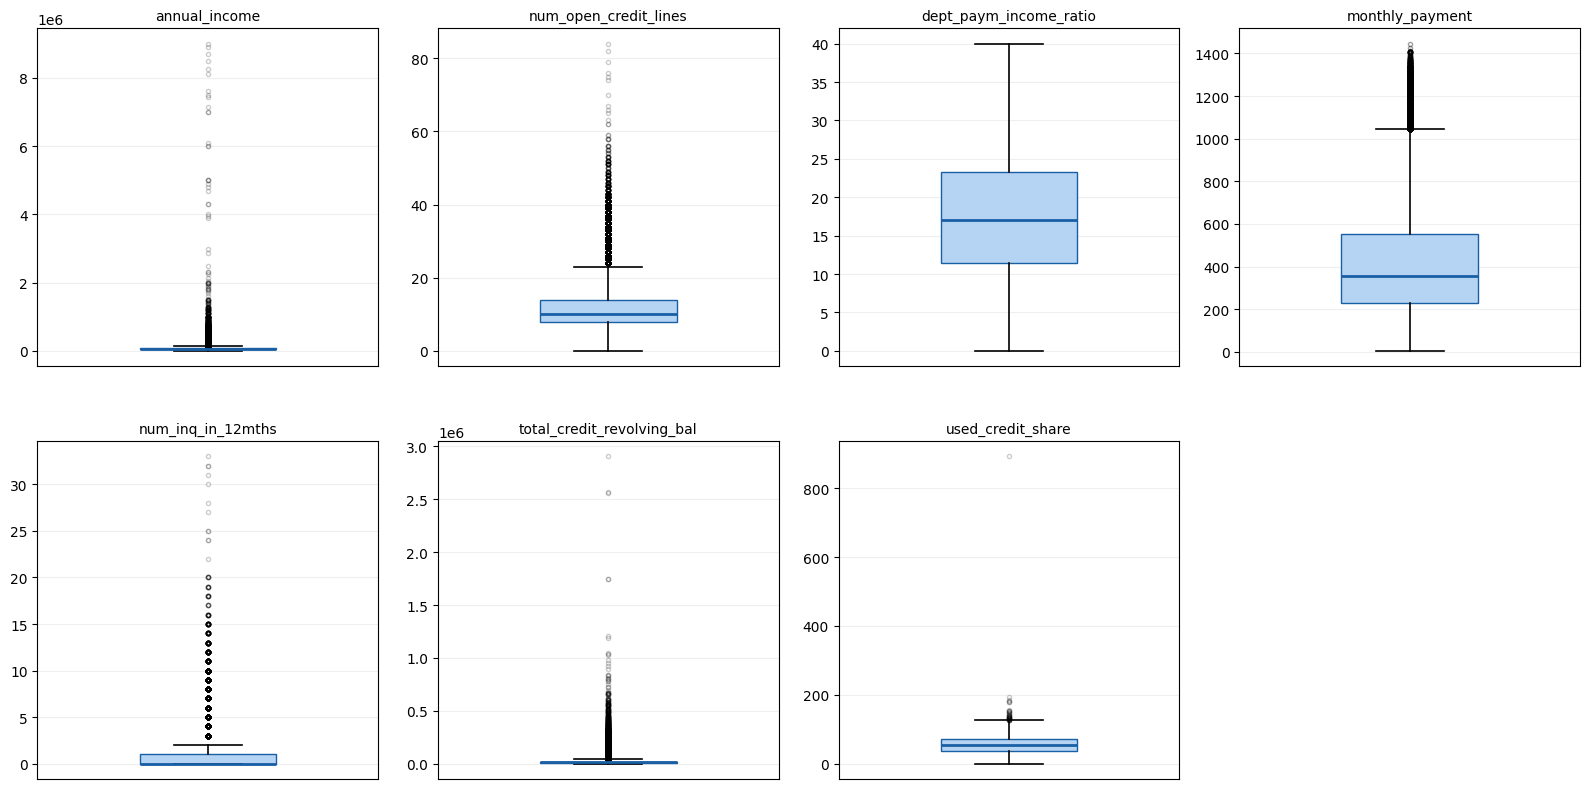

In [5]:
# Binary or categorical columns stored as numbers are one-hot encoded, not scaled
CATEGORICAL_NUMERIC = ["is_directpay_PD", "loan_term_months"]

num_features_PD = [
    f for f in df_PD[features_PD].select_dtypes(include=[np.number]).columns
    if f not in CATEGORICAL_NUMERIC
]
cat_features_PD = [f for f in features_PD if f not in num_features_PD]
print(f"Numeric: {num_features_PD}")
print(f"Categorical: {cat_features_PD}")

plot_boxplots_list(df_PD_dev, num_features_PD, cols=4)

### 3.2 Outlier Summary

In [6]:
outlier_summary_PD = outlier_summary(df_PD_dev, num_features_PD)
outlier_summary_PD

,Q1,Q3,IQR,lower_1.5,upper_1.5,lower_3.0,upper_3.0,moderate_n,moderate_pct,extreme_n,extreme_pct
feature,,,,,,,,,,,
annual_income,44000.00,88000.00,44000.00,-22000.00,154000.00,-88000.00,220000.00,30918,4.57,9978,1.48
num_open_credit_lines,8.00,14.00,6.00,-1.00,23.00,-10.00,32.00,18058,2.67,2188,0.32
dept_paym_income_ratio,11.39,23.25,11.86,-6.40,41.04,-24.19,58.83,0,0.00,0,0.00
monthly_payment,229.53,555.13,325.60,-258.87,1043.53,-747.27,1531.93,22568,3.34,0,0.00
num_inq_in_12mths,0.00,1.00,1.00,-1.50,2.50,-3.00,4.00,47480,7.02,6631,0.98
total_credit_revolving_bal,5946.00,19326.00,13380.00,-14124.00,39396.00,-34194.00,59466.00,38979,5.77,14783,2.19
used_credit_share,36.60,72.80,36.20,-17.70,127.10,-72.00,181.40,36,0.01,4,0.00


### 3.3 Treatment Decisions

The treatment of every feature the selection can return is declared once, in `PD_TREATMENTS` (`src/clean_features_PD.py`), so the code follows the selection instead of hard-coding it:

- income: cap at p99, then log1p if the skew is still above 2;
- utilisation ratios: economic ceiling at 100;
- counts and balances with long upper tails: cap at p99 (log1p discarded for balances, where the mass near zero makes it invert the skew);
- debt-to-income: negatives set to 0 (data errors);
- credit history start year: floor at p1 (lower-tail errors);
- home ownership: OTHER (0.07%) grouped into RENT, the closest economic profile;
- remaining numeric NaNs: median of the development sample.

Every parameter (quantiles, the log1p decision, medians) is fitted on the development sample and applied unchanged to the whole portfolio. The table below lists what was applied to the features selected in this run.

In [7]:
treatment_PD = fit_treatment_PD(df_PD_dev[features_PD])
df_PD_clean = df_PD[["Target_Variable_Default", "is_matured"]].join(
    treatment_PD.transform(df_PD[features_PD])
)
treatment_PD.summary()

annual_income: skew after capping 1.7658 -> log1p not applied
Numeric features without a treatment step: ['monthly_payment', 'loan_term_months']


,steps,cap_upper,log1p
feature,,,
grade,none,NaN,NaN
annual_income,"cap_upper_quantile(0.99), log1p_if_skewed(2.0)",250000.00,False
home_ownership_status,replace({'OTHER': 'RENT'}),NaN,NaN
num_open_credit_lines,cap_upper_quantile(0.99),27.00,NaN
dept_paym_income_ratio,clip_lower_value(0),NaN,NaN
monthly_payment,none,NaN,NaN
num_inq_in_12mths,cap_upper_quantile(0.99),4.00,NaN
emp_title,none,NaN,NaN
total_credit_revolving_bal,cap_upper_quantile(0.99),90073.64,NaN


In [8]:
# Post-treatment audit (development sample)
audit_PD_num_clean = dataset_audit(df_PD_clean.loc[dev_mask, num_features_PD])
audit_PD_num_clean

,dtype,n_unique,null_count,null_pct,min,max,mean,std,skew
feature,,,,,,,,,
annual_income,float64,39527,0,0.0,1896.00,250000.00,71598.2816,41273.1494,1.7658
num_open_credit_lines,int64,28,0,0.0,0.00,27.00,11.1988,4.9843,0.8809
dept_paym_income_ratio,float64,4000,0,0.0,0.00,39.99,17.5341,8.1771,0.2494
monthly_payment,float64,59972,0,0.0,4.93,1445.46,420.2674,256.7912,1.0549
num_inq_in_12mths,int64,5,0,0.0,0.00,4.00,0.7301,0.9920,1.4309
total_credit_revolving_bal,float64,59156,0,0.0,0.00,90073.64,15164.9368,14544.3246,2.5028
used_credit_share,float64,1096,0,0.0,0.00,100.00,54.1647,23.9321,-0.1582


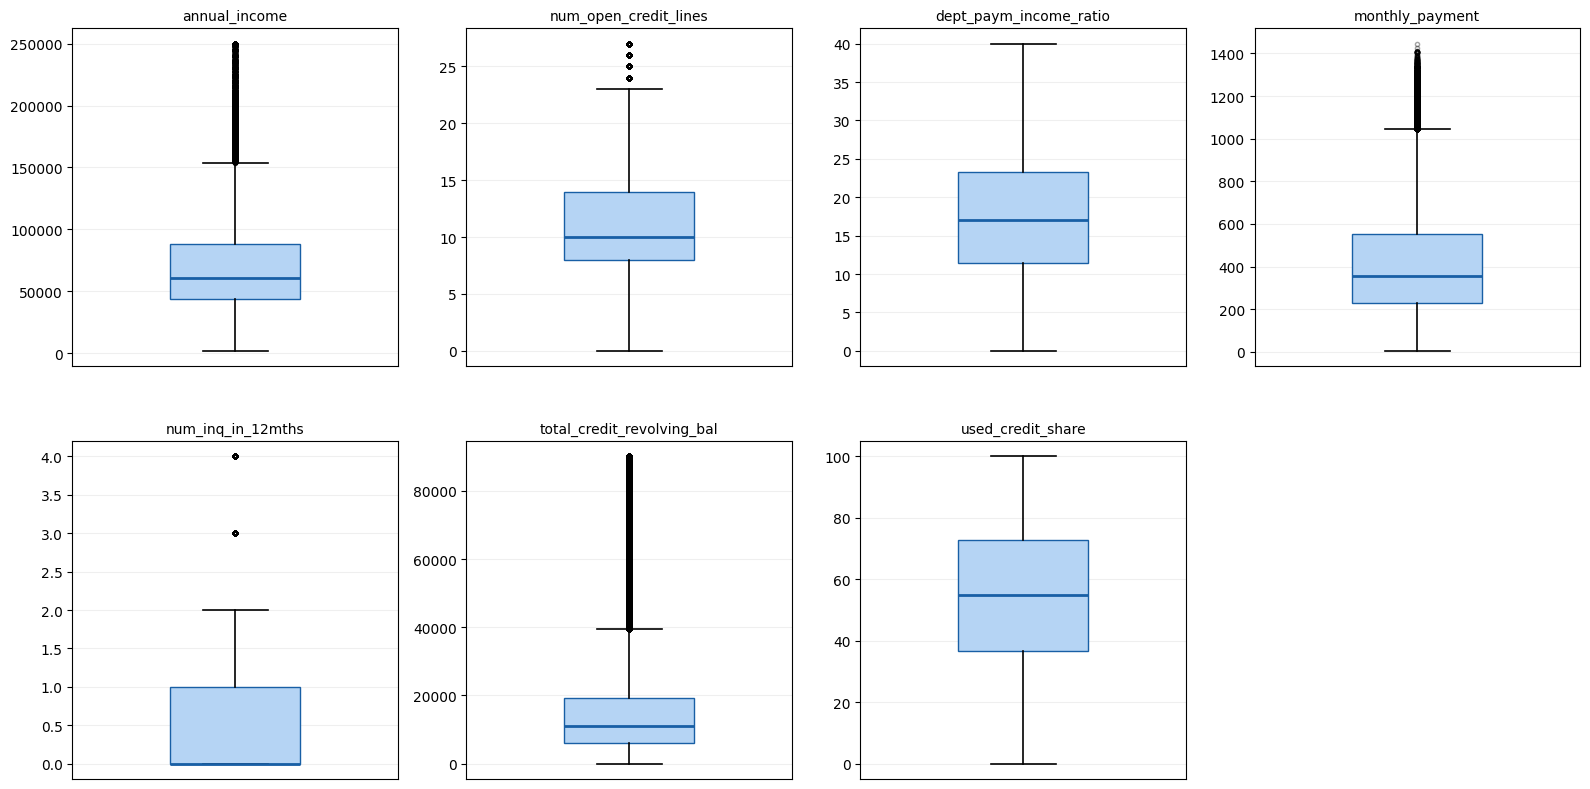

In [9]:
# Post-treatment boxplots (development sample)
plot_boxplots_list(df_PD_clean[dev_mask], num_features_PD, cols=4)

In [10]:
# Post-treatment outlier summary (development sample)
outlier_summary_PD_num_clean = outlier_summary(df_PD_clean[dev_mask], num_features_PD)
outlier_summary_PD_num_clean

,Q1,Q3,IQR,lower_1.5,upper_1.5,lower_3.0,upper_3.0,moderate_n,moderate_pct,extreme_n,extreme_pct
feature,,,,,,,,,,,
annual_income,44000.00,88000.00,44000.00,-22000.00,154000.00,-88000.00,220000.00,30918,4.57,9978,1.48
num_open_credit_lines,8.00,14.00,6.00,-1.00,23.00,-10.00,32.00,18058,2.67,0,0.00
dept_paym_income_ratio,11.39,23.25,11.86,-6.40,41.04,-24.19,58.83,0,0.00,0,0.00
monthly_payment,229.53,555.13,325.60,-258.87,1043.53,-747.27,1531.93,22568,3.34,0,0.00
num_inq_in_12mths,0.00,1.00,1.00,-1.50,2.50,-3.00,4.00,47480,7.02,0,0.00
total_credit_revolving_bal,5946.00,19326.00,13380.00,-14124.00,39396.00,-34194.00,59466.00,38979,5.77,14783,2.19
used_credit_share,36.60,72.80,36.20,-17.70,127.10,-72.00,181.40,0,0.00,0,0.00


## 4. Categorical Features

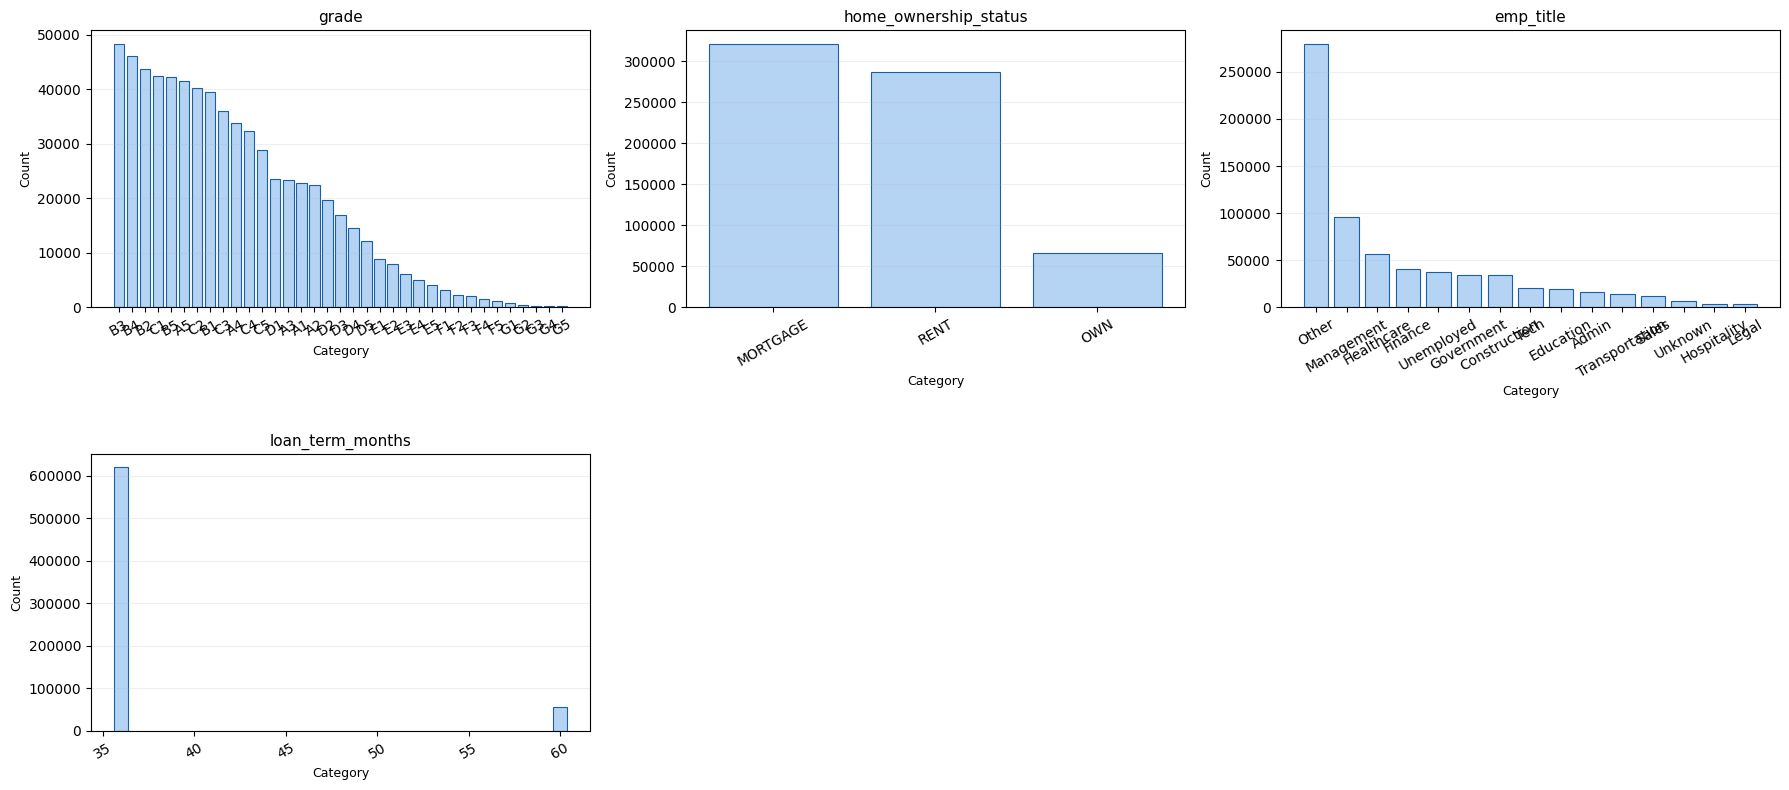

In [11]:
plot_categoricals(df_PD_clean[dev_mask], cat_features_PD, figsize_per_plot=(6, 4))

In [12]:
# Category shares after the recoding in PD_TREATMENTS (development sample)
for col in cat_features_PD:
    print(df_PD_clean.loc[dev_mask, col].value_counts(normalize=True).round(4), "\n")

grade
B3    0.0716
B4    0.0683
B2    0.0646
C1    0.0629
B5    0.0626
A5    0.0614
C2    0.0597
B1    0.0584
C3    0.0534
A4    0.0501
C4    0.0479
C5    0.0426
D1    0.0349
A3    0.0347
A1    0.0339
A2    0.0332
D2    0.0291
D3    0.0252
D4    0.0216
D5    0.0181
E1    0.0131
E2    0.0117
E3    0.0091
E4    0.0074
E5    0.0062
F1    0.0048
F2    0.0035
F3    0.0031
F4    0.0023
F5    0.0017
G1    0.0011
G2    0.0008
G3    0.0005
G4    0.0004
G5    0.0003
Name: proportion, dtype: float64 

home_ownership_status
MORTGAGE    0.4761
RENT        0.4248
OWN         0.0991
Name: proportion, dtype: float64 

emp_title
Other             0.4141
Management        0.1420
Healthcare        0.0839
Finance           0.0606
Unemployed        0.0556
Government        0.0512
Construction      0.0504
Tech              0.0298
Education         0.0291
Admin             0.0242
Transportation    0.0211
Sales             0.0180
Unknown           0.0100
Hospitality       0.0054
Legal             0.0047
Name:

## 5. Post-Treatment Correlation Check

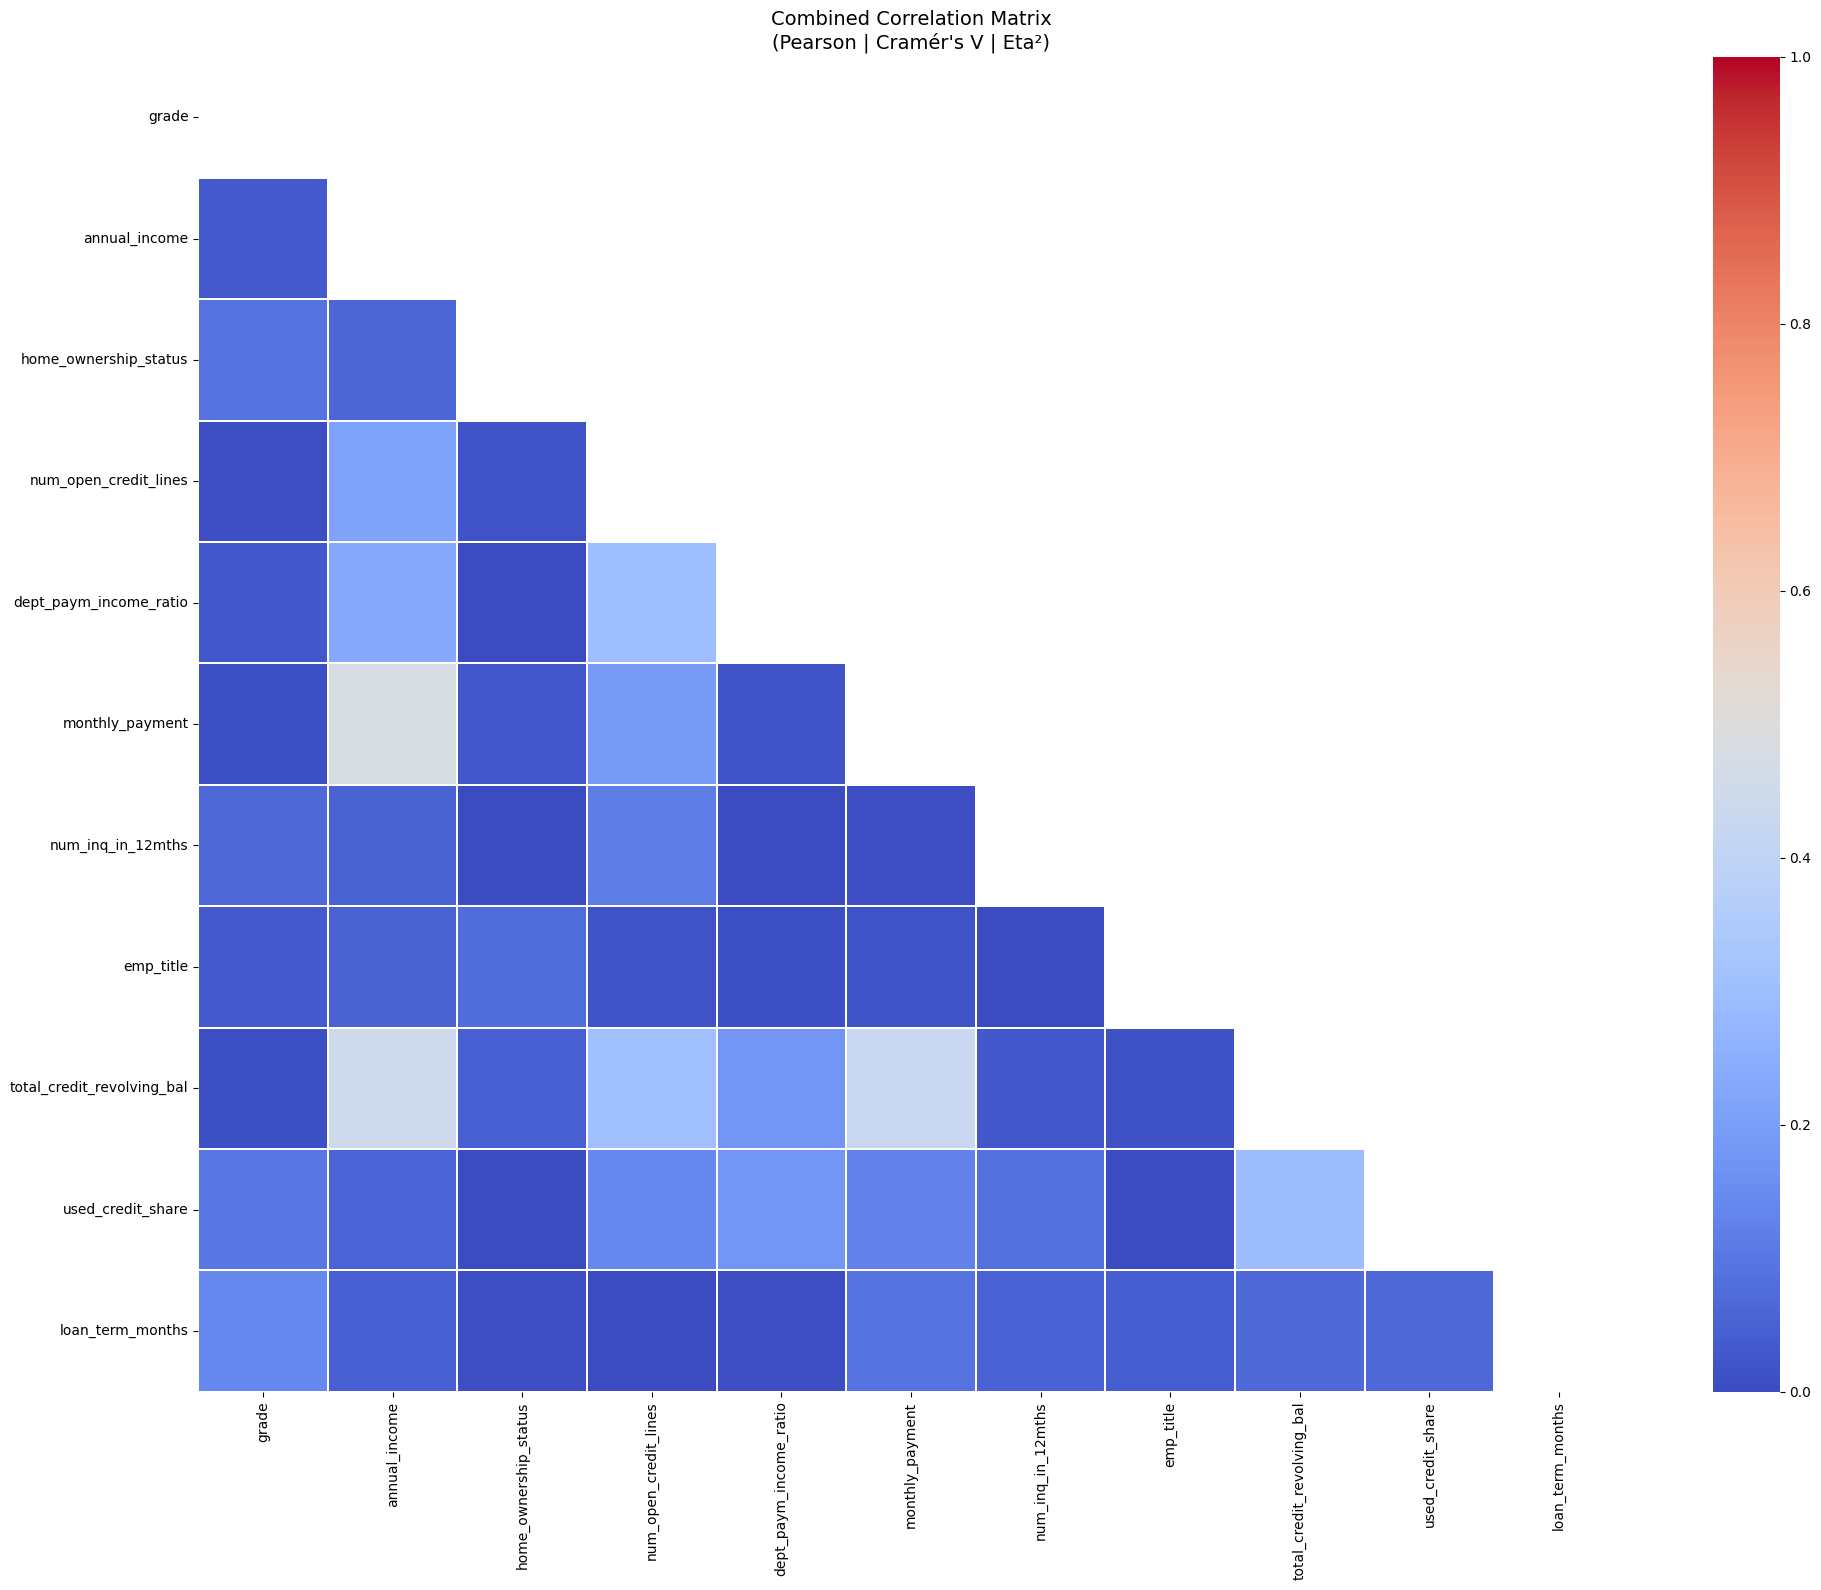

Pairs above 0.75 after treatment:
none


In [13]:
corr_matrix_PD = compute_plot_correlation_matrix(df_PD_clean.loc[dev_mask, features_PD])

# Pairs still above the 0.75 threshold used in 02_feature_selection
pairs = corr_matrix_PD.where(np.triu(np.ones(corr_matrix_PD.shape, dtype=bool), k=1)).stack()
print("Pairs above 0.75 after treatment:")
print(pairs[pairs.abs() > 0.75].round(3) if (pairs.abs() > 0.75).any() else "none")

In [14]:
# df_PD_clean holds the treated features for every loan; 05 trains on the matured ones
print(f"df_PD_clean: {df_PD_clean.shape} | matured: {int(df_PD_clean['is_matured'].sum()):,}")

df_PD_clean: (2139643, 13) | matured: 676,113


## 6. Checkpoint: Save PD Training Dataframe

In [15]:
os.makedirs("data/processed", exist_ok=True)

with open("data/processed/checkpoint_df_PD_training.pkl", "wb") as f:
    pickle.dump({"df_PD_clean": df_PD_clean}, f)

with open("data/processed/features_PD_num_for_training.pkl", "wb") as f:
    pickle.dump(num_features_PD, f)

with open("data/processed/features_PD_cat_for_training.pkl", "wb") as f:
    pickle.dump(cat_features_PD, f)

print(f"Saved. Shape: {df_PD_clean.shape}")

Saved. Shape: (2139643, 13)


In [16]:
# Load checkpoint (skip re-running)
with open("data/processed/checkpoint_df_PD_training.pkl", "rb") as f:
    data = pickle.load(f)
df_PD_clean = data["df_PD_clean"]

with open("data/processed/features_PD_num_for_training.pkl", "rb") as f:
    num_features_PD = pickle.load(f)

with open("data/processed/features_PD_cat_for_training.pkl", "rb") as f:
    cat_features_PD = pickle.load(f)